# 01 · NASA POWER daily data — diagnosis and statistical analysis

**Purpose.** Before using any other data source or building any model, understand what NASA POWER daily data can and cannot tell a farmer:
how reliable it is, how much of each variable is just the time of year, how the variables relate to each other, whether there are trends,
what the extremes look like, and whether anything is predictable beyond the seasonal average. All of it is repeated on **9 sites across the world's main farming climates**
to check that the conclusions are not specific to one place.

**Data.** NASA POWER daily point data (community AG), 2001-01-01 to 2025-12-31, 7 variables.
Main site: Ipiales, Colombia (0.83, −77.64, ~2,900 m). Comparison sites: see Section 0.

**Contents**
0. Setup and sites · 1. Variable dictionary · 2. Data quality · 3. Descriptive statistics · 4. Seasonality · 5. Dependence between variables ·
6. Persistence (memory) · 7. Interannual variability and trends · 8. Water balance (ET0, aridity, dry spells) · 9. Extremes · 10. Predictability baselines ·
11. Nine-site comparison · 12. Findings, limitations and next steps

*Conventions.* Every table is printed as plain text so it can be copied; every figure is also saved to `../figures/`. "Anomaly" = value minus the smoothed mean annual cycle of that calendar day.

## 0 · Setup and sites

In [1]:
import sys, warnings, platform
from pathlib import Path
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import climate_tools as ct
from power_client import descargar_power      # used only if a CSV is missing

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def show(obj, title, digits=2):
    """Print a table as plain text (copy-friendly)."""
    print("\n" + "=" * 110 + f"\n{title}\n" + "=" * 110)
    if isinstance(obj, dict): obj = pd.Series(obj).to_frame("value")
    fmt = lambda x: (f"{x:.{digits}f}" if (abs(x) >= 10 ** -digits or x == 0) else f"{x:.1e}")
    print(obj.to_string(float_format=fmt))

# name: (lat, lon, approximate elevation in m -- to verify, climate type)
SITES = {
    "Ipiales":   (0.83,  -77.64, 2900, "tropical highland (Andes, Colombia)"),
    "Nairobi":   (-1.29,  36.82, 1795, "tropical highland (Kenya)"),
    "Sorriso":   (-12.54, -55.71, 380, "tropical savanna / Cerrado (Brazil)"),
    "Des Moines": (41.60, -93.61, 290, "humid continental, maize belt (USA)"),
    "Ludhiana":  (30.90,  75.85,  247, "semi-arid irrigated, Punjab (India)"),
    "Niamey":    (13.51,   2.11,  220, "Sahel, monsoon (Niger)"),
    "Can Tho":   (10.03, 105.78,    2, "tropical delta, rice (Vietnam)"),
    "Mendoza":   (-32.89, -68.84, 750, "arid irrigated (Argentina)"),
    "Fallon":    (39.47, -118.78, 1240, "high desert irrigated (USA)"),
}
MAIN = "Ipiales"
DATA_DIRS = ["../data", "data", "../notebooks/data", "notebooks/data"]

data = {}
for name, (la, lo, el, _) in SITES.items():
    p = ct.find_csv(la, lo, DATA_DIRS)
    if p is None:
        print("Downloading", name); d = descargar_power(la, lo, cache_dir="../data"); d.index.name = "date"
    else:
        d = ct.load_csv(p)
    data[name] = d[ct.VARS]

meta = pd.DataFrame({k: {"lat": v[0], "lon": v[1], "elev_m(approx)": v[2], "climate": v[3],
                         "first_day": data[k].index.min().date(), "last_day": data[k].index.max().date(),
                         "days": len(data[k])} for k, v in SITES.items()}).T
show(meta, "Sites loaded")
df = data[MAIN]; LAT, LON, ELEV = SITES[MAIN][:3]
print("\nVersions: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)


Sites loaded
              lat     lon elev_m(approx)                              climate   first_day    last_day  days
Ipiales      0.83  -77.64           2900  tropical highland (Andes, Colombia)  2001-01-01  2025-12-31  9131
Nairobi     -1.29   36.82           1795            tropical highland (Kenya)  2001-01-01  2025-12-31  9131
Sorriso    -12.54  -55.71            380  tropical savanna / Cerrado (Brazil)  2001-01-01  2025-12-31  9131
Des Moines  41.60  -93.61            290  humid continental, maize belt (USA)  2001-01-01  2025-12-31  9131
Ludhiana    30.90   75.85            247  semi-arid irrigated, Punjab (India)  2001-01-01  2025-12-31  9131
Niamey      13.51    2.11            220               Sahel, monsoon (Niger)  2001-01-01  2025-12-31  9131
Can Tho     10.03  105.78              2       tropical delta, rice (Vietnam)  2001-01-01  2025-12-31  9131
Mendoza    -32.89  -68.84            750           arid irrigated (Argentina)  2001-01-01  2025-12-31  9131
Fallon      39

## 1 · Variable dictionary

In [2]:
dic = pd.DataFrame([
    ("T2M_MAX", "Daily maximum air temperature at 2 m", "°C", "MERRA-2 reanalysis"),
    ("T2M_MIN", "Daily minimum air temperature at 2 m", "°C", "MERRA-2 reanalysis"),
    ("T2M", "Daily mean air temperature at 2 m", "°C", "MERRA-2 reanalysis"),
    ("PRECTOTCORR", "Precipitation, bias-corrected (reanalysis rainfall adjusted with gauge-based products)", "mm/day", "MERRA-2 corrected"),
    ("RH2M", "Relative humidity at 2 m (daily mean)", "%", "MERRA-2 reanalysis"),
    ("WS2M", "Wind speed at 2 m", "m/s", "MERRA-2 reanalysis"),
    ("ALLSKY_SFC_SW_DWN", "Downward shortwave radiation at the surface, all-sky (includes clouds)", "MJ/m²/day", "CERES SYN1deg (satellite)"),
], columns=["variable", "meaning", "unit", "upstream product (per POWER documentation)"]).set_index("variable")
show(dic, "Variables")
print("\nNative grid (per POWER documentation; verify): MERRA-2 meteorology ≈ 0.5° × 0.625° (~55 × 70 km); CERES radiation ≈ 1° × 1° (~110 km).")
print("Consequence: values describe a ~55-110 km cell, not a farm plot. Rain and radiation come from different products and grids.")


Variables
                                                                                                  meaning       unit upstream product (per POWER documentation)
variable                                                                                                                                                       
T2M_MAX                                                              Daily maximum air temperature at 2 m         °C                         MERRA-2 reanalysis
T2M_MIN                                                              Daily minimum air temperature at 2 m         °C                         MERRA-2 reanalysis
T2M                                                                     Daily mean air temperature at 2 m         °C                         MERRA-2 reanalysis
PRECTOTCORR        Precipitation, bias-corrected (reanalysis rainfall adjusted with gauge-based products)     mm/day                          MERRA-2 corrected
RH2M                         

## 2 · Data quality

Four checks, applied to all 9 sites: completeness, physical coherence (e.g. Tmin ≤ Tmean ≤ Tmax, humidity 0–100 %), repeated values (a sign of filling), and extreme outliers
in the anomalies (|robust z| > 6, using the median absolute deviation, for the symmetric variables only).

In [3]:
rows = {}
for name, d in data.items():
    exp = (d.index.max() - d.index.min()).days + 1
    an = ct.anomalies(d)
    z = {}
    for c in ["T2M_MAX", "T2M_MIN", "T2M", "RH2M", "ALLSKY_SFC_SW_DWN"]:
        mad = (an[c] - an[c].median()).abs().median() * 1.4826
        z[c] = int(((an[c] - an[c].median()).abs() / mad > 6).sum())
    rows[name] = {
        "days_expected": exp, "days_present": len(d), "missing_cells": int(d.isna().sum().sum()),
        "viol_Tmin<=Tmean<=Tmax": int((~((d.T2M_MIN <= d.T2M + 1e-9) & (d.T2M <= d.T2M_MAX + 1e-9))).sum()),
        "viol_rain<0": int((d.PRECTOTCORR < 0).sum()),
        "viol_RH_outside_0-100": int((~d.RH2M.between(0, 100)).sum()),
        "viol_wind<0": int((d.WS2M < 0).sum()),
        "viol_SW_outside_0-45": int((~d.ALLSKY_SFC_SW_DWN.between(0, 45)).sum()),
        "repeat_prev_day_%_Tmean": 100 * (d.T2M.diff() == 0).mean(),
        "repeat_prev_day_%_RH": 100 * (d.RH2M.diff() == 0).mean(),
        "outliers_|z|>6_(5 vars)": sum(z.values()),
    }
q = pd.DataFrame(rows).T
for c_ in q.columns:
    if "%" not in c_: q[c_] = q[c_].astype(int)
show(q, "Quality checks, all sites")


Quality checks, all sites
            days_expected  days_present  missing_cells  viol_Tmin<=Tmean<=Tmax  viol_rain<0  viol_RH_outside_0-100  viol_wind<0  viol_SW_outside_0-45  repeat_prev_day_%_Tmean  repeat_prev_day_%_RH  outliers_|z|>6_(5 vars)
Ipiales              9131          9131              0                       0            0                      0            0                     0                     0.68                  0.12                        1
Nairobi              9131          9131              0                       0            0                      0            0                     0                     0.69                  0.09                        0
Sorriso              9131          9131              0                       0            0                      0            0                     0                     0.49                  0.13                       11
Des Moines           9131          9131              0                       0       

**Reading.** Zeros in the missing-cell and violation columns mean the data are complete and physically coherent. Repeated values matter for variables that cannot repeat exactly by chance;
rainfall is excluded because consecutive dry days legitimately repeat 0. The flagged "outliers" are almost all unusually *low-radiation (cloudy) days* at arid sites, where clear sky is the norm and the spread of the anomaly is tiny: real weather, not errors.

## 3 · Descriptive statistics (Ipiales)

In [4]:
def describe(d):
    t = d.describe(percentiles=[.05, .25, .5, .75, .95]).T
    t["CV_%"] = 100 * t["std"] / t["mean"]
    t["skew"] = d.skew(); t["kurtosis"] = d.kurt()
    t["zero_days_%"] = 100 * (d == 0).mean()
    k2 = {c: stats.normaltest(d[c])[0] for c in d.columns}
    t["normality_K2"] = pd.Series(k2)
    return t.drop(columns=["count"])

desc = describe(df)
show(desc, "Descriptive statistics of daily values, Ipiales 2001-2025 (n = 9,131)", 2)
print("\nNormality (D'Agostino K²): with n = 9,131 every variable rejects normality (p ≈ 0). Use rank-based or resampling methods where it matters.")


Descriptive statistics of daily values, Ipiales 2001-2025 (n = 9,131)
                   mean  std   min    5%   25%   50%   75%   95%   max   CV_%  skew  kurtosis  zero_days_%  normality_K2
T2M_MAX           17.85 1.39 12.10 15.57 16.89 17.85 18.82 20.12 22.59   7.76 -0.03     -0.15         0.00         10.94
T2M_MIN            9.71 1.19  4.42  7.69  8.92  9.77 10.56 11.54 13.59  12.25 -0.33      0.05         0.00        154.47
T2M               13.18 0.93  8.99 11.54 12.62 13.24 13.81 14.59 16.55   7.07 -0.39      0.35         0.00        248.79
PRECTOTCORR        3.03 4.49  0.00  0.00  0.35  1.38  3.79 11.55 87.99 148.52  3.96     32.79         5.39       7974.45
RH2M              85.05 4.06 65.83 77.88 82.58 85.35 87.95 91.13 95.22   4.77 -0.54      0.45         0.00        447.73
WS2M               1.82 0.94  0.19  0.61  1.05  1.65  2.43  3.53  6.56  51.78  0.77      0.30         0.00        752.04
ALLSKY_SFC_SW_DWN 13.37 3.33  3.91  8.39 10.99 13.13 15.44 19.28 26.64  24.89  0.4

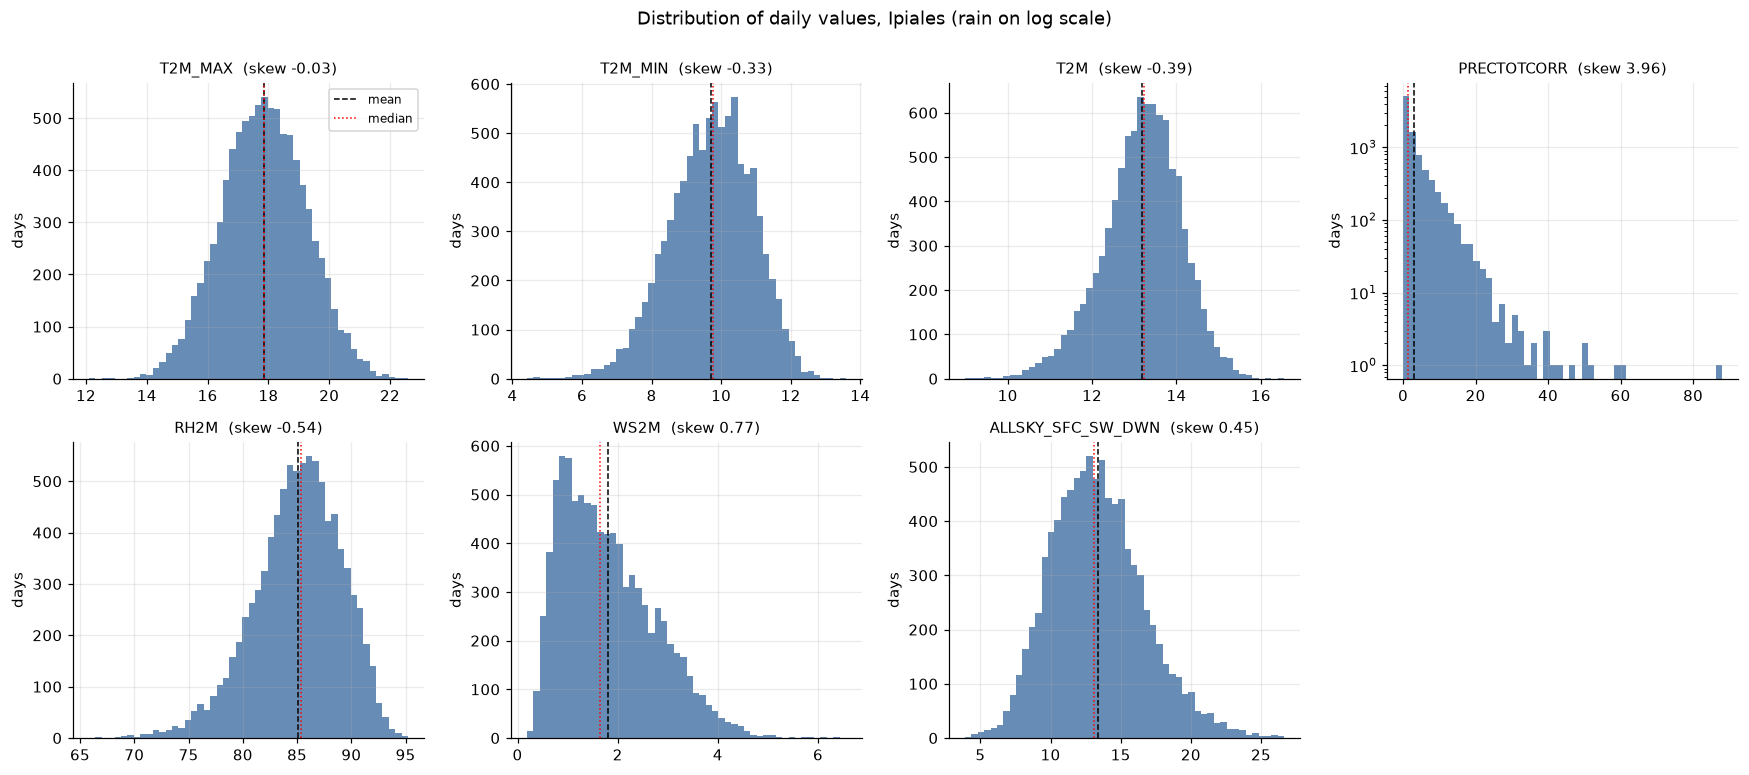

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
for ax, c in zip(axs, ct.VARS):
    ax.hist(df[c], bins=50, color="#4c78a8", alpha=.85)
    ax.axvline(df[c].mean(), color="k", lw=1, ls="--", label="mean"); ax.axvline(df[c].median(), color="r", lw=1, ls=":", label="median")
    ax.set_title(f"{c}  (skew {df[c].skew():.2f})", fontsize=10); ax.set_ylabel("days")
    if c == "PRECTOTCORR": ax.set_yscale("log")
axs[0].legend(fontsize=8); axs[-1].axis("off")
fig.suptitle("Distribution of daily values, Ipiales (rain on log scale)", y=1.0); plt.tight_layout(); savefig("01_histograms_ipiales"); plt.show()

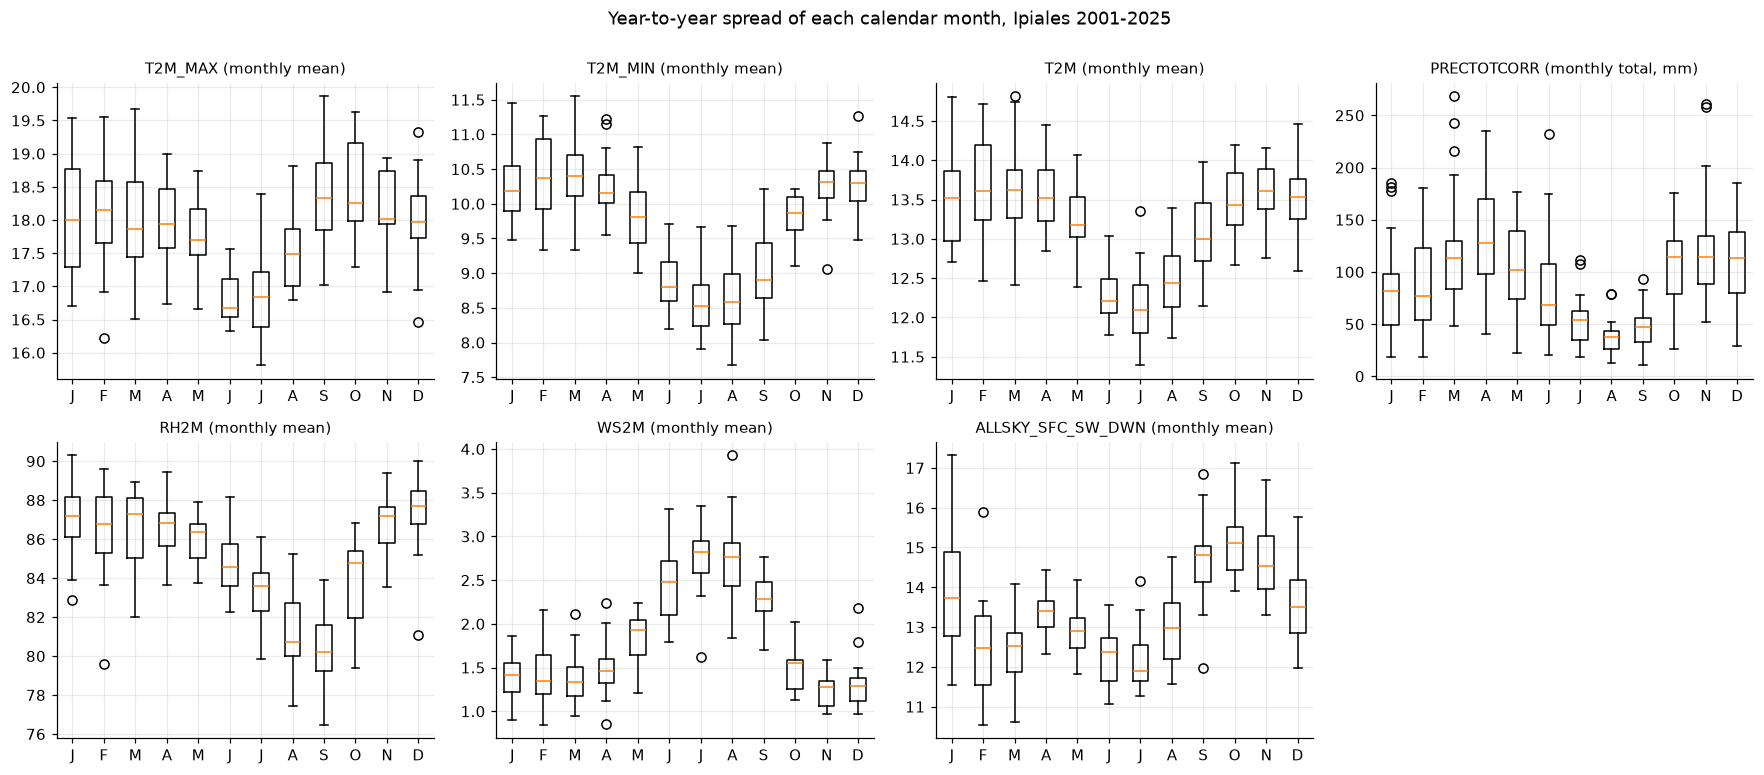

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
for ax, c in zip(axs, ct.VARS):
    m = ct.monthly_series(df, c)
    ax.boxplot([m[m.index.month == k].values for k in range(1, 13)], showfliers=True); ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.set_title(c + (" (monthly total, mm)" if c == "PRECTOTCORR" else " (monthly mean)"), fontsize=10)
axs[-1].axis("off")
fig.suptitle("Year-to-year spread of each calendar month, Ipiales 2001-2025", y=1.0); plt.tight_layout(); savefig("02_monthly_boxplots_ipiales"); plt.show()

### 3b · Rainfall regime


Wet-day statistics (wet day = rain ≥ 1 mm), Ipiales
                      value
wet_day_freq          0.573
mean_wet_intensity    5.033
median_wet_intensity  3.210
p95_wet              14.310
gamma_shape           1.592
gamma_scale           3.161
ks_stat               0.100

Daily rain intensity classes, Ipiales
             days_per_year  share_of_days_%  share_of_total_rain_%
PRECTOTCORR                                                       
<1 mm               155.96            42.70                   4.66
1-5                 138.72            37.98                  30.70
5-10                 45.00            12.32                  28.88
10-20                21.96             6.01                  26.64
20-50                 3.40             0.93                   7.98
>=50                  0.20             0.05                   1.13


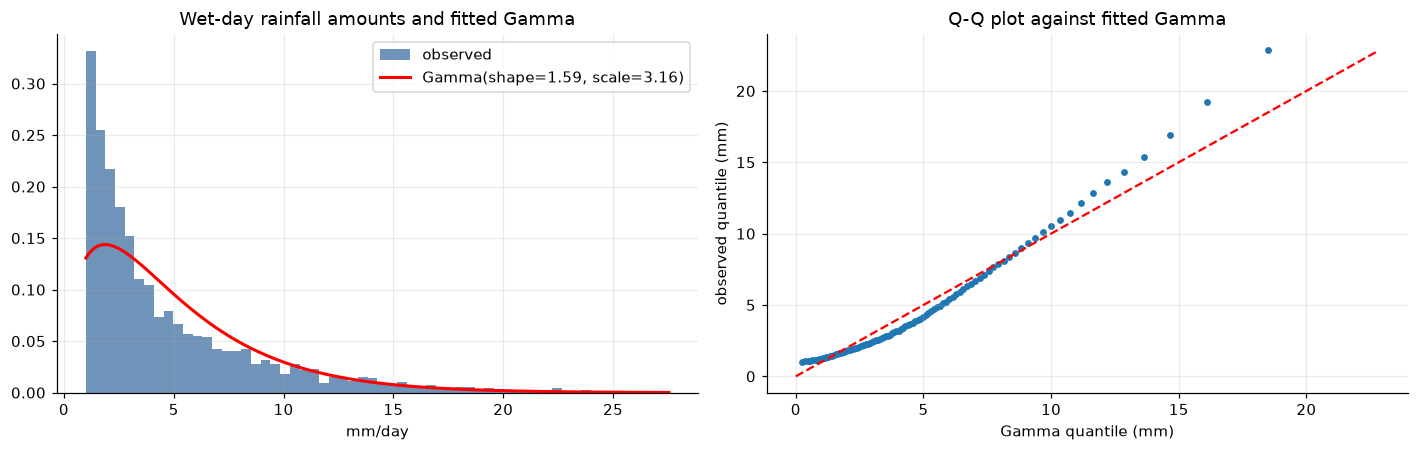

KS statistic = 0.100 (p-values from a KS test with fitted parameters are optimistic; judge the fit from the Q-Q plot).


In [7]:
rain = df.PRECTOTCORR
w = ct.wet_day_stats(rain, 1.0)
show(w, "Wet-day statistics (wet day = rain ≥ 1 mm), Ipiales", 3)

bins = [0, 1, 5, 10, 20, 50, 1e9]; labels = ["<1 mm", "1-5", "5-10", "10-20", "20-50", ">=50"]
cls = pd.cut(rain, bins, right=False, labels=labels)
cls_tab = pd.DataFrame({"days_per_year": cls.value_counts().sort_index() / 25,
                        "share_of_days_%": 100 * cls.value_counts(normalize=True).sort_index(),
                        "share_of_total_rain_%": 100 * rain.groupby(cls).sum() / rain.sum()})
show(cls_tab, "Daily rain intensity classes, Ipiales")

wet = rain[rain >= 1]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.linspace(1, wet.quantile(.995), 200)
axs[0].hist(wet, bins=60, range=(1, wet.quantile(.995)), density=True, alpha=.8, color="#4c78a8", label="observed")
axs[0].plot(x, stats.gamma.pdf(x, w["gamma_shape"], 0, w["gamma_scale"]), "r", lw=2, label=f"Gamma(shape={w['gamma_shape']:.2f}, scale={w['gamma_scale']:.2f})")
axs[0].set_title("Wet-day rainfall amounts and fitted Gamma"); axs[0].set_xlabel("mm/day"); axs[0].legend()
q = np.linspace(.01, .99, 99)
axs[1].scatter(stats.gamma.ppf(q, w["gamma_shape"], 0, w["gamma_scale"]), wet.quantile(q), s=12)
lim = max(wet.quantile(.99), 1); axs[1].plot([0, lim], [0, lim], "r--"); axs[1].set_title("Q-Q plot against fitted Gamma"); axs[1].set_xlabel("Gamma quantile (mm)"); axs[1].set_ylabel("observed quantile (mm)")
plt.tight_layout(); savefig("03_rain_gamma_ipiales"); plt.show()
print(f"KS statistic = {w['ks_stat']:.3f} (p-values from a KS test with fitted parameters are optimistic; judge the fit from the Q-Q plot).")

## 4 · Seasonality

How much of each variable is just "the time of year"? Two measures: (a) the share of variance explained by the mean annual cycle (daily and monthly scale), and (b) a Kruskal–Wallis test of whether the 12 calendar months differ, with effect size η²_H.

In [8]:
mon = pd.DataFrame({
    "rain_mm_mean": ct.monthly_series(df, "PRECTOTCORR").groupby(lambda d: d.month).mean(),
    "rain_mm_sd":   ct.monthly_series(df, "PRECTOTCORR").groupby(lambda d: d.month).std(),
    "Tmax": df.T2M_MAX.groupby(df.index.month).mean(), "Tmin": df.T2M_MIN.groupby(df.index.month).mean(),
    "Tmean": df.T2M.groupby(df.index.month).mean(), "RH_%": df.RH2M.groupby(df.index.month).mean(),
    "wind": df.WS2M.groupby(df.index.month).mean(), "SW_MJ": df.ALLSKY_SFC_SW_DWN.groupby(df.index.month).mean()})
mon.index.name = "month"
show(mon, "Monthly climatology, Ipiales (rain: mean monthly total ± inter-annual sd)")

kw = pd.DataFrame({c: dict(zip(["H", "p_value", "eta2_H"], ct.kruskal_by_month(
        ct.monthly_series(df, c)))) for c in ct.VARS}).T
kw["seasonal_share_daily"] = ct.seasonal_share(df)
kw["seasonal_share_monthly"] = ct.seasonal_share(df, "MS")
show(kw, "Seasonality: Kruskal-Wallis across months (on monthly values) and share of variance explained by the annual cycle", 4)


Monthly climatology, Ipiales (rain: mean monthly total ± inter-annual sd)
       rain_mm_mean  rain_mm_sd  Tmax  Tmin  Tmean  RH_%  wind  SW_MJ
month                                                                
1             88.06       46.02 18.04 10.23  13.54 86.93  1.41  13.97
2             89.13       42.62 18.16 10.42  13.68 86.53  1.41  12.47
3            121.23       57.40 18.05 10.41  13.63 86.62  1.38  12.34
4            132.31       49.72 17.98 10.26  13.56 86.60  1.49  13.38
5            106.05       43.42 17.76  9.82  13.25 86.05  1.83  12.87
6             87.58       49.49 16.81  8.86  12.31 84.79  2.44  12.25
7             53.51       23.03 16.86  8.57  12.14 83.39  2.73  12.13
8             37.76       16.39 17.54  8.63  12.49 81.22  2.75  12.97
9             47.81       21.53 18.38  8.99  13.07 80.31  2.29  14.65
10           104.96       35.28 18.50  9.84  13.49 83.98  1.49  15.14
11           126.10       54.34 18.20 10.25  13.56 86.78  1.23  14.66
12           11

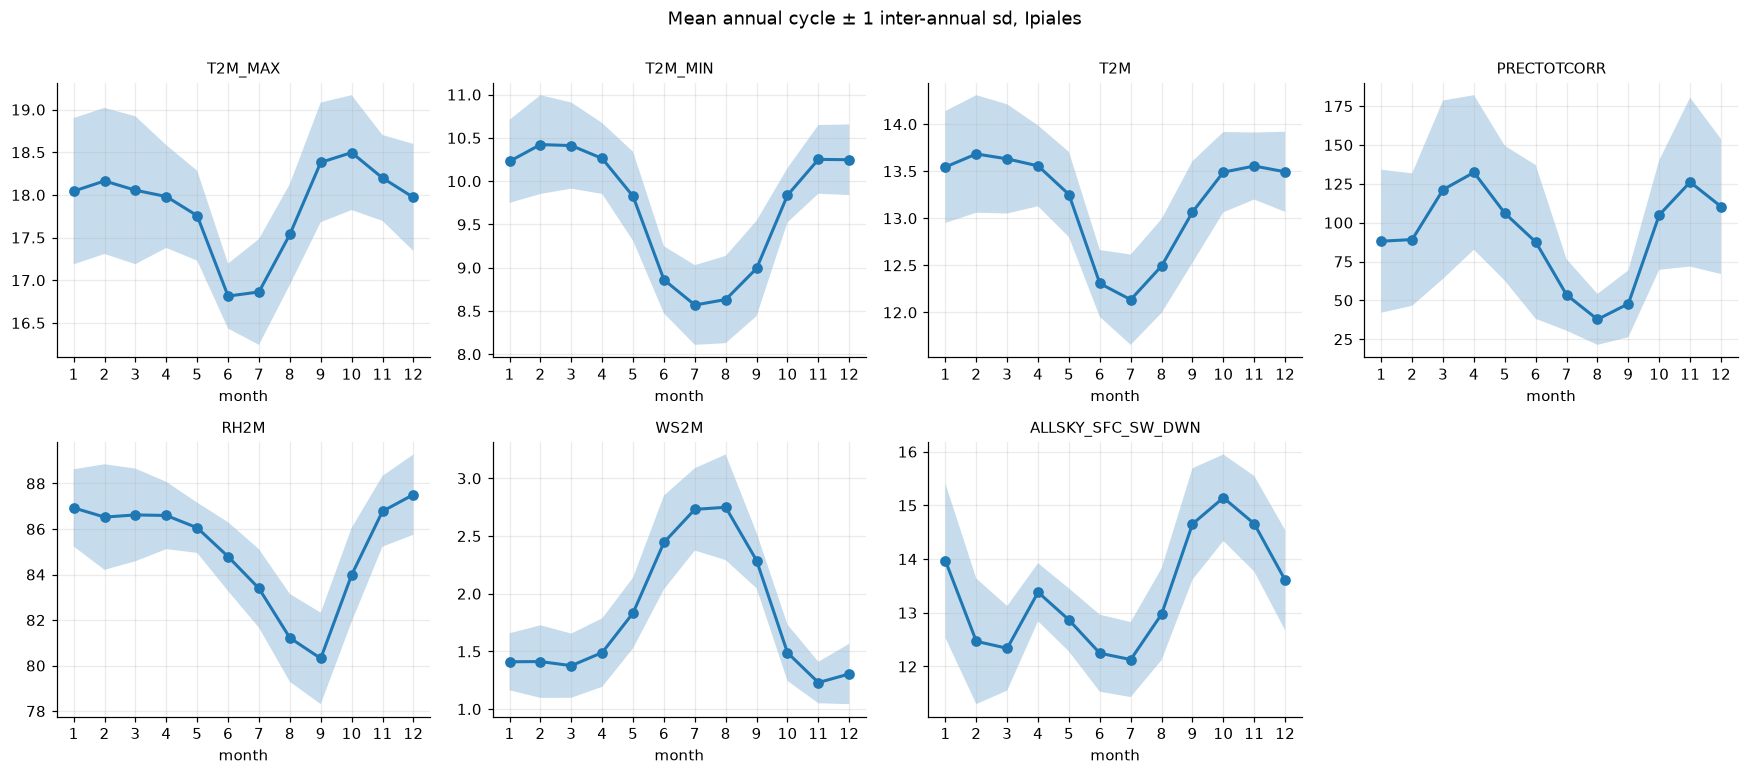

In [9]:
fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
for ax, c in zip(axs, ct.VARS):
    m = ct.monthly_series(df, c)
    g = m.groupby(m.index.month); mu, sd = g.mean(), g.std()
    ax.plot(mu.index, mu.values, "o-", lw=2); ax.fill_between(mu.index, mu - sd, mu + sd, alpha=.25)
    ax.set_title(c, fontsize=10); ax.set_xticks(range(1, 13)); ax.set_xlabel("month")
axs[-1].axis("off")
fig.suptitle("Mean annual cycle ± 1 inter-annual sd, Ipiales", y=1.0); plt.tight_layout(); savefig("04_seasonal_cycle_ipiales"); plt.show()

## 5 · Dependence between variables

Computed on **anomalies** (seasonal cycle removed), because raw correlations are dominated by the calendar. Pearson measures linear association, Spearman monotonic association.
Daily anomalies are serially correlated, so ordinary p-values are too optimistic: confidence intervals use a **moving-block bootstrap** (30-day blocks).

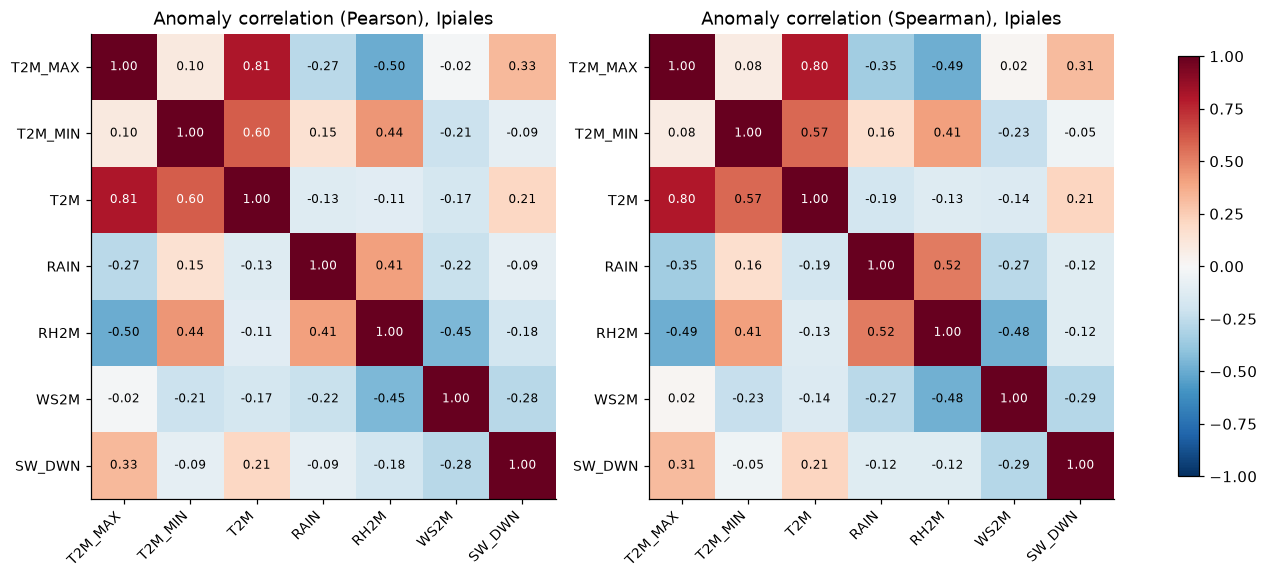


Pearson correlation of daily anomalies, Ipiales
                   T2M_MAX  T2M_MIN   T2M  PRECTOTCORR  RH2M  WS2M  ALLSKY_SFC_SW_DWN
T2M_MAX               1.00     0.10  0.81        -0.27 -0.50 -0.02               0.33
T2M_MIN               0.10     1.00  0.60         0.15  0.44 -0.21              -0.09
T2M                   0.81     0.60  1.00        -0.13 -0.11 -0.17               0.21
PRECTOTCORR          -0.27     0.15 -0.13         1.00  0.41 -0.22              -0.09
RH2M                 -0.50     0.44 -0.11         0.41  1.00 -0.45              -0.18
WS2M                 -0.02    -0.21 -0.17        -0.22 -0.45  1.00              -0.28
ALLSKY_SFC_SW_DWN     0.33    -0.09  0.21        -0.09 -0.18 -0.28               1.00

Spearman correlation of daily anomalies, Ipiales
                   T2M_MAX  T2M_MIN   T2M  PRECTOTCORR  RH2M  WS2M  ALLSKY_SFC_SW_DWN
T2M_MAX               1.00     0.08  0.80        -0.35 -0.49  0.02               0.31
T2M_MIN               0.08     1.00  0.57

In [10]:
an = ct.anomalies(df)
cp, cs = an.corr("pearson"), an.corr("spearman")
short = {c: c.replace("ALLSKY_SFC_SW_DWN", "SW_DWN").replace("PRECTOTCORR", "RAIN") for c in ct.VARS}
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, M, t in zip(axs, [cp, cs], ["Pearson", "Spearman"]):
    im = ax.imshow(M.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(7)); ax.set_xticklabels([short[c] for c in M.columns], rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(7)); ax.set_yticklabels([short[c] for c in M.index], fontsize=9)
    for i in range(7):
        for j in range(7): ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="k" if abs(M.values[i, j]) < .6 else "w")
    ax.set_title(f"Anomaly correlation ({t}), Ipiales"); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=.8); savefig("05_anomaly_correlation_ipiales"); plt.show()
show(cp, "Pearson correlation of daily anomalies, Ipiales"); show(cs, "Spearman correlation of daily anomalies, Ipiales")

In [11]:
pairs = [("PRECTOTCORR", "RH2M"), ("PRECTOTCORR", "T2M_MAX"), ("PRECTOTCORR", "T2M_MIN"), ("PRECTOTCORR", "ALLSKY_SFC_SW_DWN"),
         ("T2M_MAX", "T2M_MIN"), ("T2M_MIN", "RH2M"), ("T2M_MAX", "RH2M"), ("T2M_MAX", "ALLSKY_SFC_SW_DWN"), ("RH2M", "WS2M")]
rows = {}
for a, b in pairs:
    lo, hi = ct.block_bootstrap_corr(an[a], an[b], block=30, B=1000)
    rows[f"{short[a]} ~ {short[b]}"] = {"pearson_r": an[a].corr(an[b]), "block_boot_lo": lo, "block_boot_hi": hi,
                                         "CI_excludes_0": not (lo <= 0 <= hi), "shared_variance_r2_%": 100 * an[a].corr(an[b]) ** 2}
show(pd.DataFrame(rows).T, "Selected pairs: Pearson r with 95% moving-block-bootstrap CI (Ipiales)", 3)


Selected pairs: Pearson r with 95% moving-block-bootstrap CI (Ipiales)
                  pearson_r block_boot_lo block_boot_hi CI_excludes_0 shared_variance_r2_%
RAIN ~ RH2M           0.413         0.389         0.437          True               17.032
RAIN ~ T2M_MAX       -0.272        -0.297        -0.248          True                7.383
RAIN ~ T2M_MIN        0.151         0.125         0.177          True                2.287
RAIN ~ SW_DWN        -0.088        -0.107        -0.067          True                0.768
T2M_MAX ~ T2M_MIN     0.098         0.057         0.135          True                0.960
T2M_MIN ~ RH2M        0.438         0.401         0.476          True               19.175
T2M_MAX ~ RH2M       -0.500        -0.532        -0.468          True               24.984
T2M_MAX ~ SW_DWN      0.328         0.299         0.356          True               10.751
RH2M ~ WS2M          -0.450        -0.476        -0.423          True               20.239


## 6 · Persistence (memory)

If today's anomaly helps predict tomorrow's, there is something to forecast. The autocorrelation function (ACF) of anomalies is shown up to 60 days. The grey band is the naive ±1.96/√n limit for white noise;
the **Ljung–Box** test checks jointly whether the first 10 or 30 autocorrelations are zero.

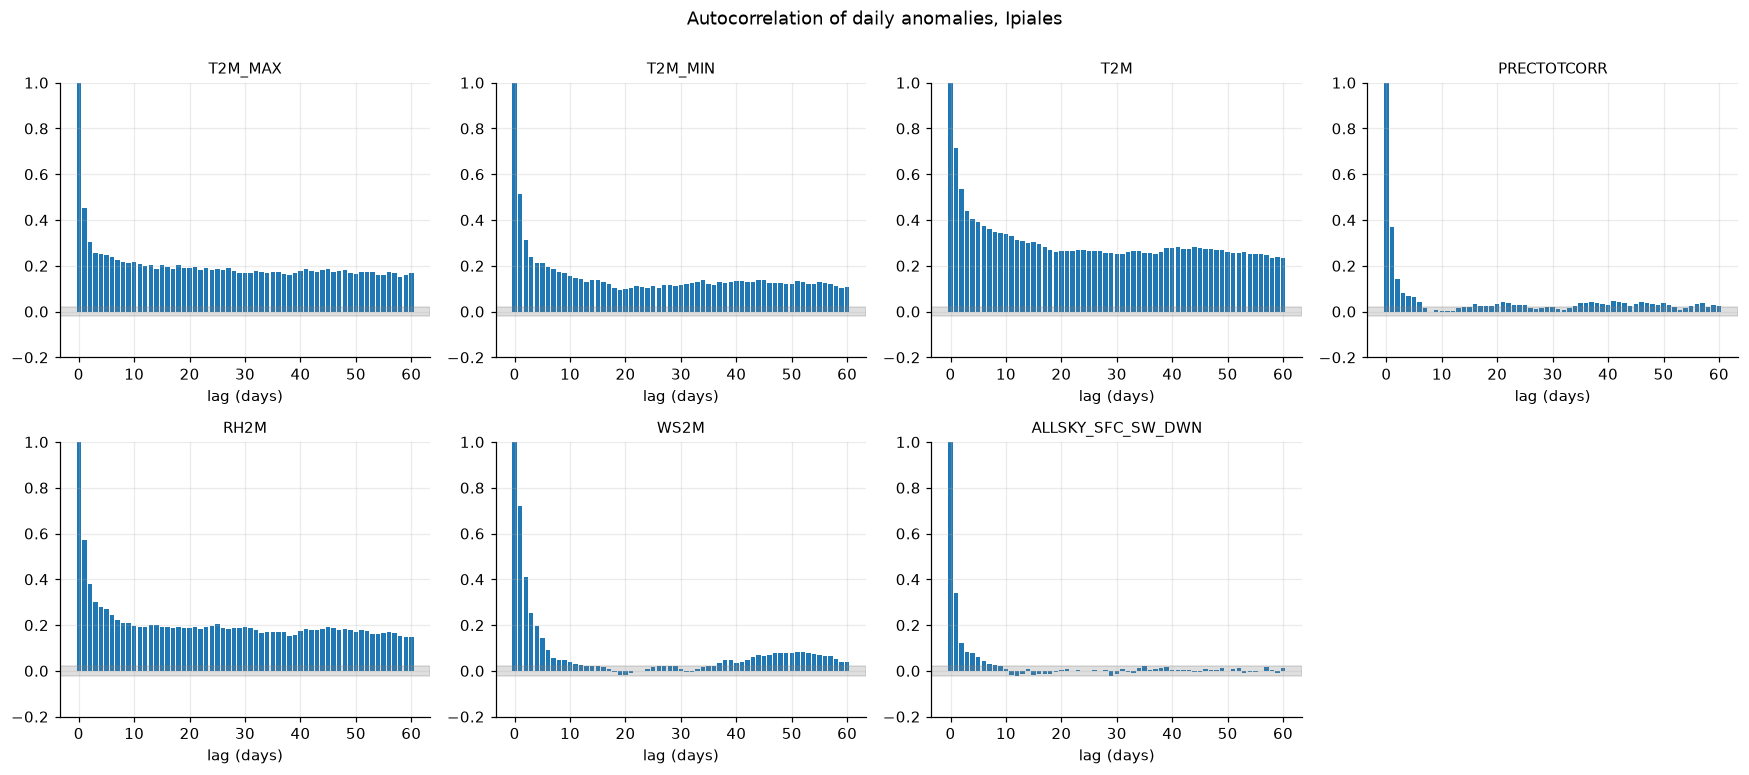


ACF of daily anomalies and Ljung-Box tests, Ipiales
                   lag1  lag2  lag3  lag7  lag14  lag30  lag60  LjungBox_Q10    p_Q10  LjungBox_Q30    p_Q30
T2M_MAX           0.454 0.306 0.256 0.226  0.188  0.167  0.168      6739.903    0.000     13301.732    0.000
T2M_MIN           0.514 0.313 0.237 0.186  0.138  0.114  0.106      6057.540    0.000      8616.450    0.000
T2M               0.715 0.534 0.440 0.361  0.301  0.252  0.236     17633.922    0.000     31833.047    0.000
PRECTOTCORR       0.369 0.143 0.083 0.014  0.021  0.021  0.023      1590.772    0.000      1698.095    0.000
RH2M              0.573 0.380 0.302 0.222  0.202  0.192  0.150      8674.630    0.000     15410.315    0.000
WS2M              0.720 0.408 0.255 0.058  0.020  0.009  0.040      7539.261    0.000      7593.155    0.000
ALLSKY_SFC_SW_DWN 0.341 0.120 0.082 0.030  0.010 -0.012  0.014      1378.814 3.7e-290      1404.642 8.0e-277


In [12]:
nl = 60
fig, axs = plt.subplots(2, 4, figsize=(16, 7)); axs = axs.ravel()
acf_tab = {}
for ax, c in zip(axs, ct.VARS):
    a = ct.acf(an[c], nl); band = 1.96 / np.sqrt(len(an))
    ax.bar(range(nl + 1), a, width=.8); ax.axhspan(-band, band, color="grey", alpha=.25)
    ax.set_title(c, fontsize=10); ax.set_xlabel("lag (days)"); ax.set_ylim(-.2, 1)
    acf_tab[c] = {f"lag{l}": a[l] for l in [1, 2, 3, 7, 14, 30, 60]}
    for L in (10, 30):
        Q, p = ct.ljung_box(an[c], L); acf_tab[c][f"LjungBox_Q{L}"] = Q; acf_tab[c][f"p_Q{L}"] = p
axs[-1].axis("off"); fig.suptitle("Autocorrelation of daily anomalies, Ipiales", y=1.0); plt.tight_layout(); savefig("06_acf_ipiales"); plt.show()
show(pd.DataFrame(acf_tab).T, "ACF of daily anomalies and Ljung-Box tests, Ipiales", 3)

## 7 · Interannual variability and trends

Annual values for 2001–2025 (n = 25). Trends use the **Mann–Kendall** test (Kendall τ against time) and the **Theil–Sen** slope with 95 % CI. Because 9 variables are tested,
p-values are also adjusted with **Holm's** method. A split-period comparison (2001–2013 vs 2014–2025) uses Mann–Whitney.
*Caution:* reanalysis products can contain artificial shifts when the observing system changes, so a significant trend is a flag to investigate, not proof of climate change.

In [13]:
at, et0 = ct.annual_table(df, LAT, ELEV)
show(at, "Annual indicators, Ipiales", 2)
print("\nInter-annual mean and variability")
show(pd.DataFrame({"mean": at.mean(), "sd": at.std(), "CV_%": 100 * at.std() / at.mean(), "min": at.min(), "max": at.max()}), "Summary of annual indicators", 2)


Annual indicators, Ipiales
      rain_mm  ET0_mm  Tmean_C  Tmax_C  Tmin_C  RH_%  wind_ms  SW_MJ  wet_days  heavy_days_>12.7mm  max_daily_rain_mm  frost_days_Tmin<=2C  frost_days_Tmin<=0C  longest_dry_spell_d  P/ET0  P-ET0_mm
date                                                                                                                                                                                                 
2001   736.96  910.16    13.08   18.09    9.40 83.02     2.15  13.65       169                   5              40.16                    0                    0                   25   0.81   -173.20
2002   927.64  903.24    13.24   18.28    9.49 82.87     2.03  13.37       178                  15              87.99                    0                    0                   19   1.03     24.40
2003   957.78  859.22    13.20   18.06    9.58 84.36     1.87  12.77       194                  12              52.50                    0                    0                   14

In [14]:
tv = ["Tmax_C", "Tmin_C", "Tmean_C", "rain_mm", "ET0_mm", "RH_%", "wind_ms", "SW_MJ", "wet_days"]
tr = pd.DataFrame({v: ct.trend_test(at.index.values, at[v].values) for v in tv}).T
order = tr.p.sort_values().index
holm = pd.Series(index=order, dtype=float); m = len(tr); prev = 0
for i, k in enumerate(order):
    prev = max(prev, min(1, (m - i) * tr.p[k])); holm[k] = prev
tr["p_Holm"] = holm
tr["sig_5%_raw"] = tr.p < .05; tr["sig_5%_Holm"] = tr.p_Holm < .05
shift = pd.DataFrame({v: ct.period_shift(at[v], 2014) for v in tv}).T
show(tr[["tau", "p", "p_Holm", "sen_slope_per_yr", "ci_lo", "ci_hi", "sig_5%_raw", "sig_5%_Holm"]], "Trend tests on annual values (Mann-Kendall, Theil-Sen), Ipiales", 4)
show(shift, "Early (2001-2013) vs late (2014-2025) periods, Mann-Whitney, Ipiales", 4)


Trend tests on annual values (Mann-Kendall, Theil-Sen), Ipiales
             tau      p  p_Holm  sen_slope_per_yr   ci_lo   ci_hi  sig_5%_raw  sig_5%_Holm
Tmax_C   -0.0600 0.6943  1.0000           -0.0089 -0.0322  0.0206       False        False
Tmin_C    0.2933 0.0413  0.2476            0.0177 8.2e-05  0.0334        True        False
Tmean_C   0.1267 0.3914  1.0000            0.0070 -0.0108  0.0293       False        False
rain_mm   0.3867 0.0063  0.0505           19.7067  7.9020 29.8113        True        False
ET0_mm   -0.1067 0.4730  1.0000           -0.8867 -1.9759  0.8225       False        False
RH_%      0.3867 0.0063  0.0505            0.0870  0.0254  0.1594        True        False
wind_ms  -0.1067 0.4730  1.0000           -0.0035 -0.0128  0.0076       False        False
SW_MJ     0.1000 0.5022  1.0000            0.0055 -0.0186  0.0292       False        False
wet_days  0.4441 0.0019  0.0170            2.6450  1.2500  4.1111        True         True

Early (2001-2013) vs lat

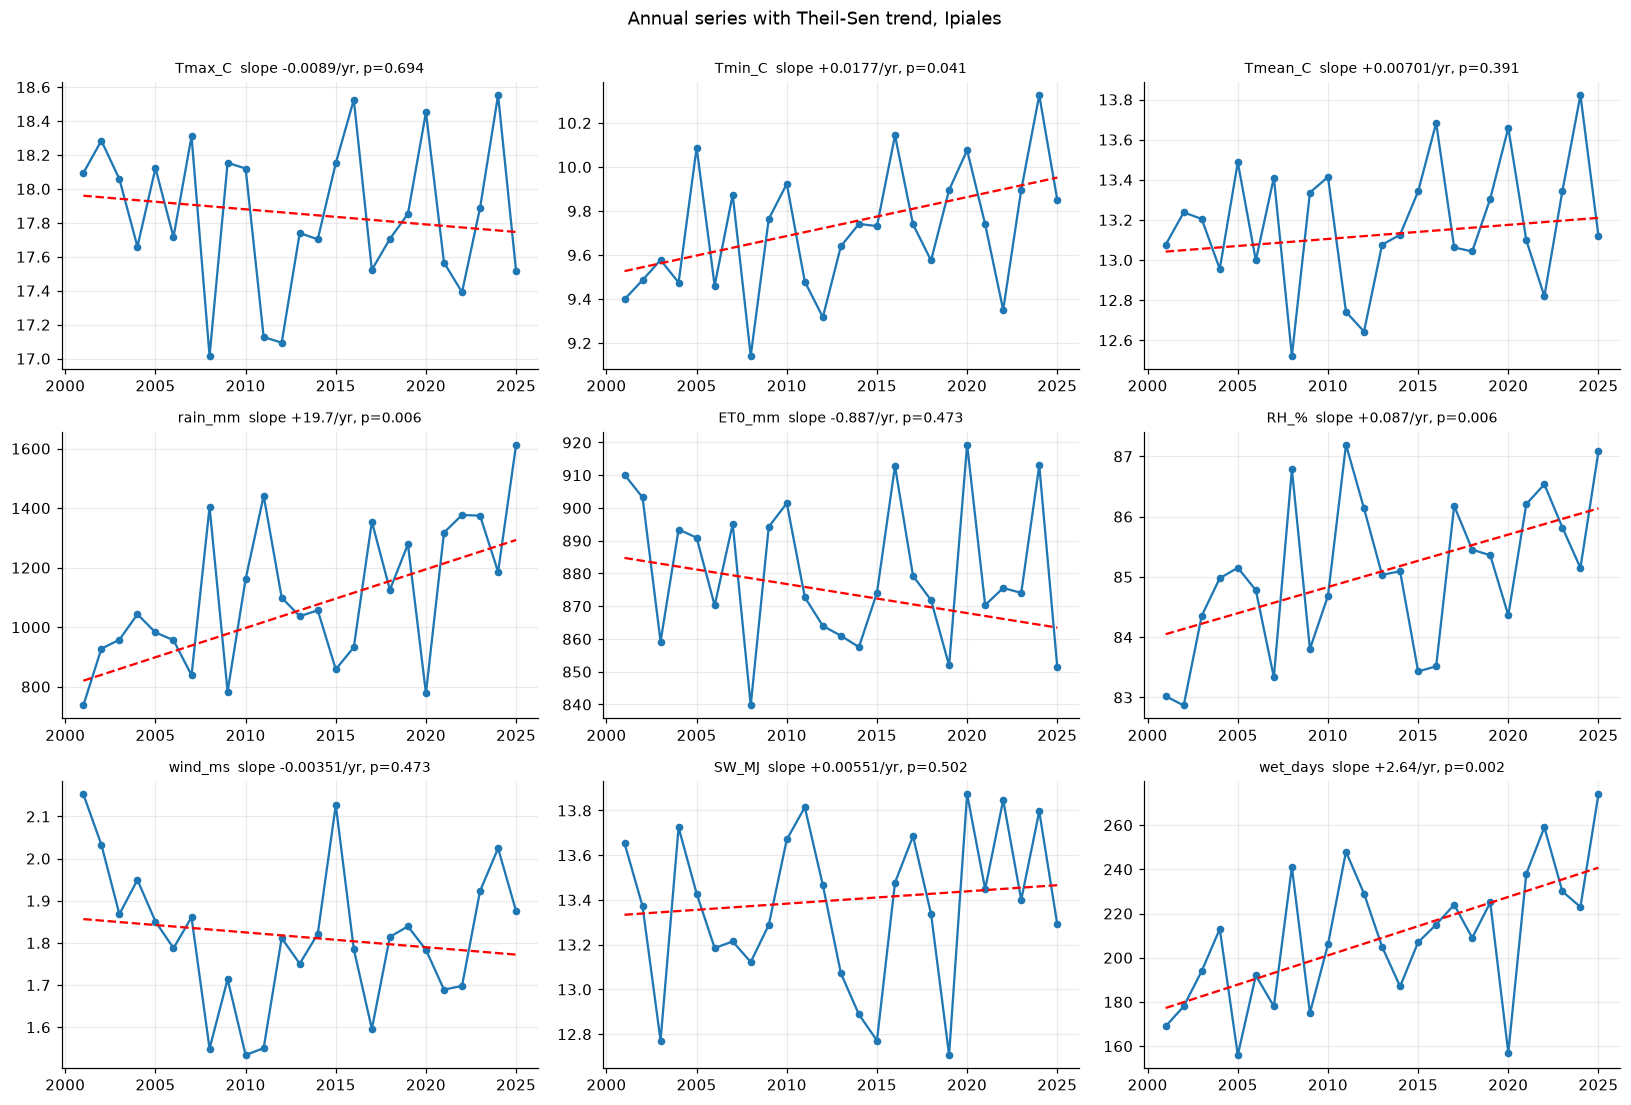

In [15]:
fig, axs = plt.subplots(3, 3, figsize=(15, 10)); axs = axs.ravel()
for ax, v in zip(axs, tv):
    ax.plot(at.index, at[v], "o-", ms=4)
    t = tr.loc[v]; ax.plot(at.index, t.intercept + t.sen_slope_per_yr * at.index.values, "r--", lw=1.5)
    ax.set_title(f"{v}  slope {t.sen_slope_per_yr:+.3g}/yr, p={t.p:.3f}", fontsize=9)
fig.suptitle("Annual series with Theil-Sen trend, Ipiales", y=1.0); plt.tight_layout(); savefig("07_annual_trends_ipiales"); plt.show()

## 8 · Water balance: ET0, aridity and dry spells

Reference evapotranspiration (ET0) by FAO-56 Penman–Monteith (`climate_tools.et0_fao56`), validated first against the worked example in the FAO manual (Example 18, Uccle, Belgium: ET0 ≈ 3.9 mm/day).
Then P − ET0, the aridity index P/ET0 (UNEP classes), the distribution of dry spells, and a variance decomposition: how much of the year-to-year variability of the water balance comes from rainfall versus evaporative demand.

In [16]:
ex = pd.DataFrame({"T2M_MAX": [21.5], "T2M_MIN": [12.3], "T2M": [16.9], "RH2M": [73.5], "WS2M": [2.78], "ALLSKY_SFC_SW_DWN": [22.07]},
                  index=pd.to_datetime(["2020-07-06"]))
print(f"FAO-56 example 18: computed ET0 = {float(ct.et0_fao56(ex, 50.8, 100).iloc[0]):.2f} mm/day (manual: 3.9)")

d8 = df.copy(); d8["ET0"] = et0
mm = d8[["PRECTOTCORR", "ET0"]].resample("MS").sum(); mm["P_minus_ET0"] = mm.PRECTOTCORR - mm.ET0
bal = pd.DataFrame({"rain_mm": mm.PRECTOTCORR.groupby(mm.index.month).mean(), "ET0_mm": mm.ET0.groupby(mm.index.month).mean(),
                    "P-ET0_mm": mm.P_minus_ET0.groupby(mm.index.month).mean(),
                    "%_years_with_P<ET0": 100 * (mm.P_minus_ET0 < 0).groupby(mm.index.month).mean()}); bal.index.name = "month"
show(bal, "Monthly water balance climatology, Ipiales")

P, E = at.rain_mm, at.ET0_mm
dec = {"Var(P)": P.var(), "Var(ET0)": E.var(), "2*Cov(P,ET0)": 2 * np.cov(P, E)[0, 1], "Var(P-ET0)": (P - E).var(),
       "share of Var(P-ET0) due to P (%)": 100 * P.var() / (P - E).var(), "corr(P, ET0)": np.corrcoef(P, E)[0, 1],
       "mean P/ET0": P.mean() / E.mean(), "UNEP class": ct.aridity_class(P.mean() / E.mean())}
show(dec, "Variance decomposition of the annual water balance P - ET0, Ipiales", 3)
print("Years with P < ET0:", list(at.index[at.rain_mm < at.ET0_mm]))

sp = ct.spell_lengths(rain, 1.0)
spq = pd.Series(sp).describe(percentiles=[.5, .75, .9, .95, .99]); spq["n_spells"] = len(sp)
show(spq.to_frame("dry spell length (days, rain < 1 mm)"), "Distribution of ALL dry spells, Ipiales")

FAO-56 example 18: computed ET0 = 3.85 mm/day (manual: 3.9)

Monthly water balance climatology, Ipiales
       rain_mm  ET0_mm  P-ET0_mm  %_years_with_P<ET0
month                                               
1        88.06   76.35     11.71               44.00
2        89.13   65.40     23.73               32.00
3       121.23   71.44     49.79               12.00
4       132.31   72.41     59.91               12.00
5       106.05   71.17     34.88               24.00
6        87.58   64.96     22.62               40.00
7        53.51   68.09    -14.58               80.00
8        37.76   75.03    -37.27               92.00
9        47.81   80.91    -33.09               88.00
10      104.96   83.68     21.28               36.00
11      126.10   76.68     49.42               12.00
12      110.37   74.14     36.22               24.00

Variance decomposition of the annual water balance P - ET0, Ipiales
                                     value
Var(P)                           56828.084

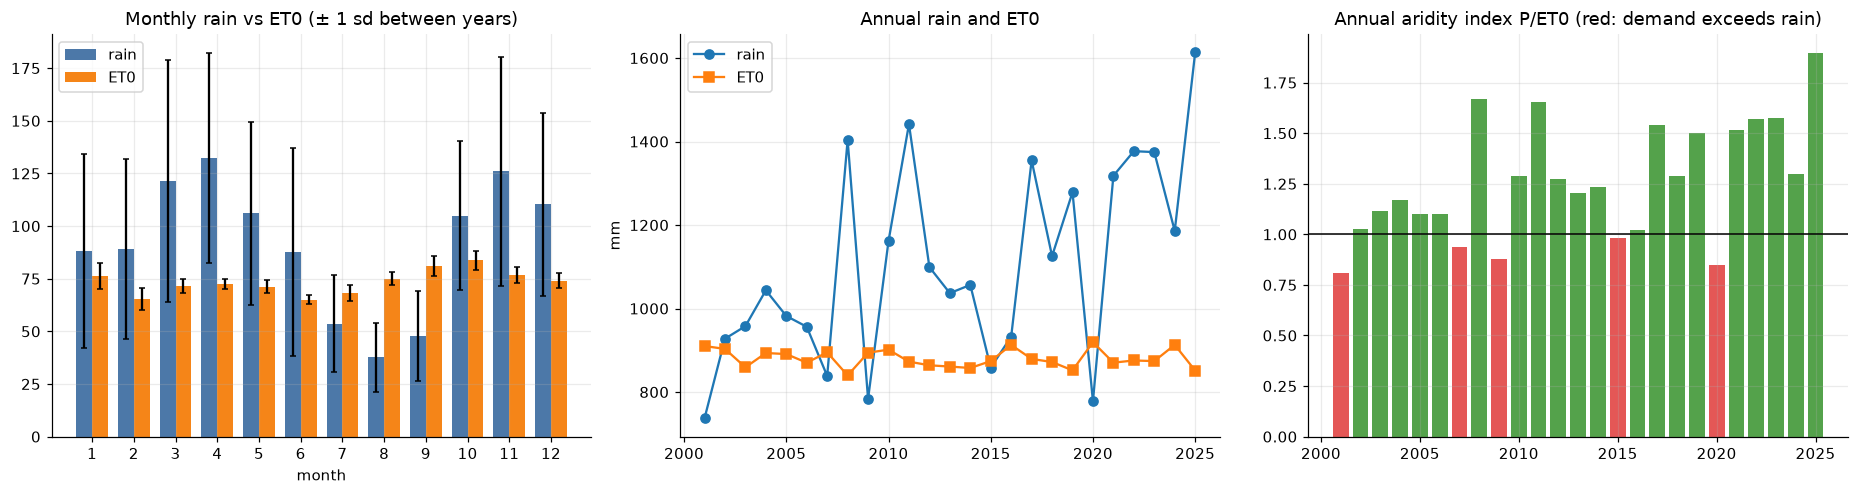

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
x = bal.index; w_ = .38
mmm = mm.groupby(mm.index.month)
axs[0].bar(x - w_/2, bal.rain_mm, w_, yerr=mmm.PRECTOTCORR.std(), label="rain", color="#4c78a8", capsize=2)
axs[0].bar(x + w_/2, bal.ET0_mm, w_, yerr=mmm.ET0.std(), label="ET0", color="#f58518", capsize=2)
axs[0].set_title("Monthly rain vs ET0 (± 1 sd between years)"); axs[0].set_xlabel("month"); axs[0].set_xticks(range(1, 13)); axs[0].legend()
axs[1].plot(at.index, at.rain_mm, "o-", label="rain"); axs[1].plot(at.index, at.ET0_mm, "s-", label="ET0")
axs[1].set_title("Annual rain and ET0"); axs[1].set_ylabel("mm"); axs[1].legend()
axs[2].bar(at.index, at["P/ET0"], color=np.where(at["P/ET0"] < 1, "#e45756", "#54a24b")); axs[2].axhline(1, color="k", lw=1)
axs[2].set_title("Annual aridity index P/ET0 (red: demand exceeds rain)")
plt.tight_layout(); savefig("08_water_balance_ipiales"); plt.show()

## 9 · Extremes

Annual maximum daily rainfall is fitted with a Gumbel distribution; return levels (5, 10, 25 years) carry parametric-bootstrap 95 % intervals.
With only 25 annual maxima the intervals are wide — that width is itself a result. Cold extremes are summarised by counts below several temperature thresholds.


Daily-rain return levels, Gumbel(loc=29.5, scale=9.5), Ipiales
                     return_level_mm  CI95_lo  CI95_hi
return_period_years                                   
5                              43.79    37.53    50.60
10                             50.94    42.71    59.35
25                             59.97    48.83    70.95

Cold-threshold counts on POWER Tmin, Ipiales
      days_Tmin<=thr (25 yr total)  days_per_year
8 °C                           740          29.60
6 °C                            27           1.08
5 °C                             5           0.20
4 °C                             0           0.00
2 °C                             0           0.00
0 °C                             0           0.00

Record values, Ipiales
                          value
lowest Tmin (°C)           4.42
date of lowest Tmin  2003-07-14
highest Tmax (°C)         22.59
wettest day (mm)          87.99
date of wettest day  2002-06-19


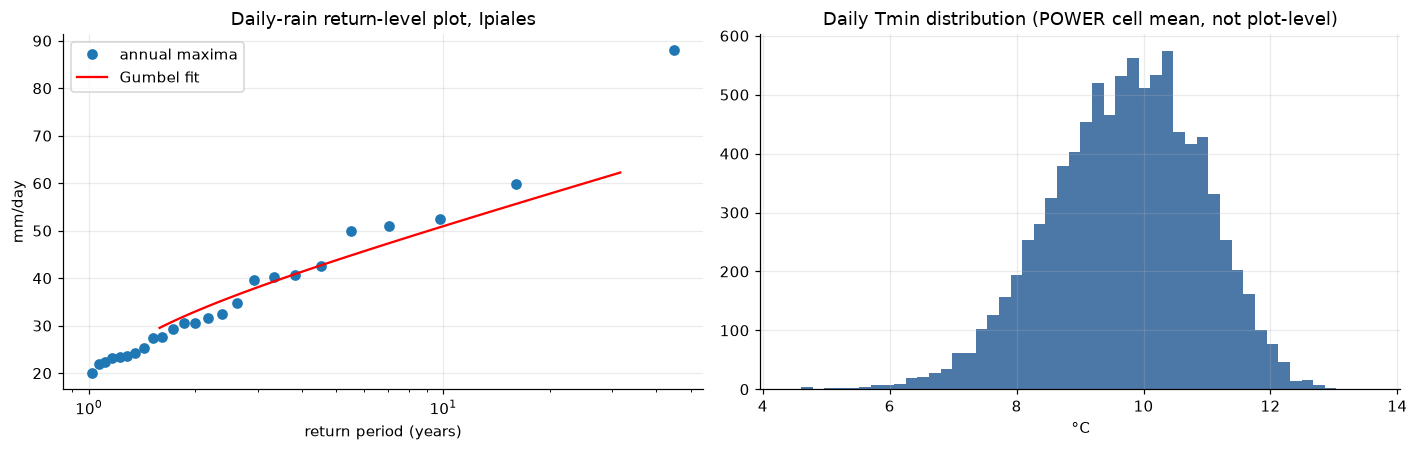

In [18]:
res, (loc, scale) = ct.annual_max_return_levels(at.max_daily_rain_mm.values, periods=(5, 10, 25), B=1000)
rl = pd.DataFrame(res, index=["return_level_mm", "CI95_lo", "CI95_hi"]).T; rl.index.name = "return_period_years"
show(rl, f"Daily-rain return levels, Gumbel(loc={loc:.1f}, scale={scale:.1f}), Ipiales")

thr = [8, 6, 5, 4, 2, 0]
cold = pd.DataFrame({"days_Tmin<=thr (25 yr total)": [(df.T2M_MIN <= t).sum() for t in thr],
                     "days_per_year": [(df.T2M_MIN <= t).sum() / 25 for t in thr]}, index=[f"{t} °C" for t in thr])
show(cold, "Cold-threshold counts on POWER Tmin, Ipiales")
ext = pd.Series({"lowest Tmin (°C)": df.T2M_MIN.min(), "date of lowest Tmin": str(df.T2M_MIN.idxmin().date()),
                 "highest Tmax (°C)": df.T2M_MAX.max(), "wettest day (mm)": rain.max(), "date of wettest day": str(rain.idxmax().date())})
show(ext.to_frame("value"), "Record values, Ipiales")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
am = at.max_daily_rain_mm.sort_values().values; pp = (np.arange(1, 26) - .44) / (25 + .12); T = 1 / (1 - pp)
axs[0].semilogx(T, am, "o", label="annual maxima"); Tg = np.logspace(.2, 1.5, 100)
axs[0].semilogx(Tg, stats.gumbel_r.ppf(1 - 1 / Tg, loc, scale), "r-", label="Gumbel fit"); axs[0].set_xlabel("return period (years)"); axs[0].set_ylabel("mm/day"); axs[0].legend()
axs[0].set_title("Daily-rain return-level plot, Ipiales")
axs[1].hist(df.T2M_MIN, bins=50, color="#4c78a8"); axs[1].set_title("Daily Tmin distribution (POWER cell mean, not plot-level)"); axs[1].set_xlabel("°C")
plt.tight_layout(); savefig("09_extremes_ipiales"); plt.show()

## 10 · Predictability baselines

Is anything forecastable beyond the seasonal average? Leave-one-year-out comparison on **monthly** series, for each year the models are fitted on the other 24:

* **climatology** — mean of that calendar month in other years (the baseline to beat);
* **persistence** — last month's value;
* **clim+AR1** — climatology plus a fitted fraction of last month's anomaly.

Skill = 1 − MSE/MSE_climatology; positive means better than climatology. Then the specific hypothesis *"does Jan–Mar rainfall anticipate Apr–Dec rainfall?"* is tested with Pearson, Spearman, bootstrap CI and a permutation test.


Leave-one-year-out forecast skill of monthly values, Ipiales
                                 MAE   RMSE     R2  skill_vs_clim
variable          model                                          
PRECTOTCORR       climatology 32.866 43.096  0.289          0.000
                  persistence 43.433 57.240 -0.255         -0.764
                  clim+AR1    32.260 42.096  0.321          0.046
T2M               climatology  0.405  0.497  0.519          0.000
                  persistence  0.416  0.536  0.441         -0.162
                  clim+AR1     0.290  0.367  0.738          0.454
T2M_MIN           climatology  0.378  0.472  0.681          0.000
                  persistence  0.478  0.616  0.457         -0.704
                  clim+AR1     0.316  0.399  0.772          0.285
T2M_MAX           climatology  0.554  0.681  0.332          0.000
                  persistence  0.538  0.670  0.353          0.032
                  clim+AR1     0.389  0.490  0.654          0.482
RH2M          

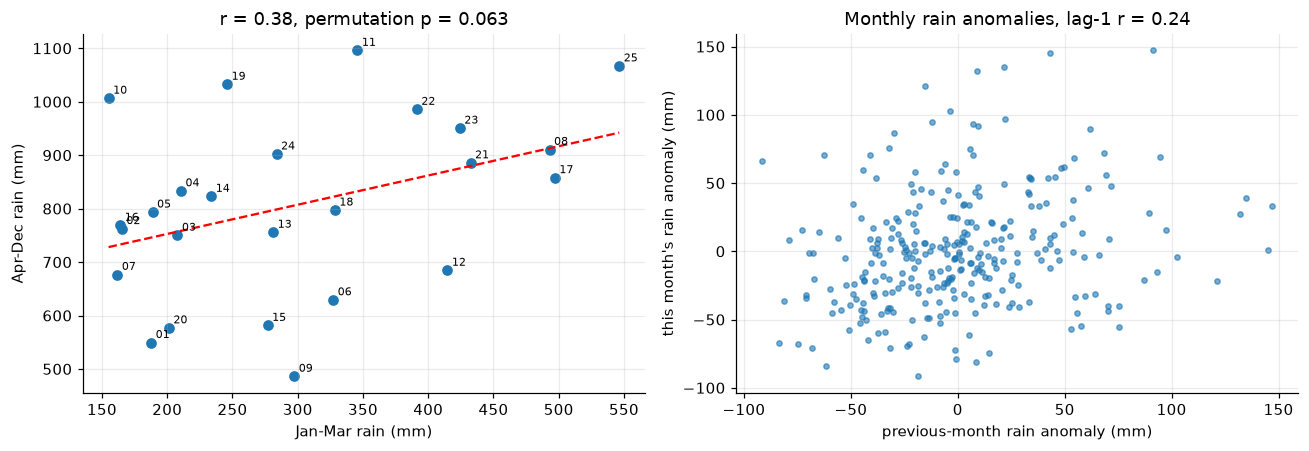

In [19]:
d10 = df.copy(); d10["ET0"] = et0
sk = {}
for c in ["PRECTOTCORR", "T2M", "T2M_MIN", "T2M_MAX", "RH2M", "ALLSKY_SFC_SW_DWN", "ET0"]:
    t = ct.loyo_skill(ct.monthly_series(d10, c))
    for mdl in t.index: sk[(c, mdl)] = t.loc[mdl]
sk = pd.DataFrame(sk).T; sk.index.names = ["variable", "model"]
show(sk, "Leave-one-year-out forecast skill of monthly values, Ipiales", 3)

q1 = ct.q1_vs_rest(rain)
show(q1, "Jan-Mar rainfall vs Apr-Dec rainfall (n = 25 years), Ipiales", 3)
a_ = rain[rain.index.month <= 3].groupby(rain[rain.index.month <= 3].index.year).sum()
b_ = rain[rain.index.month > 3].groupby(rain[rain.index.month > 3].index.year).sum()
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
axs[0].scatter(a_, b_); sl = np.polyfit(a_, b_, 1); xx = np.linspace(a_.min(), a_.max(), 10); axs[0].plot(xx, np.polyval(sl, xx), "r--")
for y, xv, yv in zip(a_.index, a_, b_): axs[0].annotate(str(y)[2:], (xv, yv), fontsize=7, xytext=(3, 3), textcoords="offset points")
axs[0].set_xlabel("Jan-Mar rain (mm)"); axs[0].set_ylabel("Apr-Dec rain (mm)"); axs[0].set_title(f"r = {q1['pearson_r']:.2f}, permutation p = {q1['perm_p']:.3f}")
mr = ct.monthly_series(df, "PRECTOTCORR"); ma = mr - mr.groupby(mr.index.month).transform("mean")
axs[1].scatter(ma.shift(1), ma, s=12, alpha=.6); axs[1].set_xlabel("previous-month rain anomaly (mm)"); axs[1].set_ylabel("this month's rain anomaly (mm)")
axs[1].set_title(f"Monthly rain anomalies, lag-1 r = {ma.autocorr(1):.2f}")
plt.tight_layout(); savefig("10_predictability_ipiales"); plt.show()

## 11 · Nine-site comparison

The same diagnostics on all sites: do the conclusions from Ipiales hold elsewhere, and what changes with climate type?

In [20]:
summ = pd.DataFrame({n: ct.site_summary(data[n], SITES[n][0], SITES[n][2]) for n in SITES}).T
num = [c for c in summ.columns if c != "aridity_class"]
summ[num] = summ[num].astype(float)
show(summ.T, "Site summary (columns = sites)", 2)


Site summary (columns = sites)
                            Ipiales    Nairobi Sorriso Des Moines   Ludhiana     Niamey Can Tho Mendoza  Fallon
rain_mm_yr                  1104.88     580.80 1502.37     856.77     733.46     554.99 1604.81  283.33  173.98
rain_CV_%                     21.58      24.59   23.03      21.53      33.13      18.60   34.94   29.86   35.40
ET0_mm_yr                    880.26    1721.70 1333.48     955.35    1740.46    2541.65 1576.09 1808.20 1382.86
ET0_CV_%                       2.49       4.16    2.28      11.85       6.43       2.72    6.73    5.40    4.19
P/ET0                          1.26       0.34    1.13       0.90       0.42       0.22    1.02    0.16    0.13
aridity_class                 humid  semi-arid   humid      humid  semi-arid  semi-arid   humid    arid    arid
share_Var(P-ET0)_from_P_%     89.85      48.81   88.39      42.00      48.44      41.39   81.81   24.53   31.75
Tmean_C                       13.18      20.18   25.72      10.39      2

In [21]:
tests = {}
for n in SITES:
    a_, _ = ct.annual_table(data[n], SITES[n][0], SITES[n][2])
    tp = ct.trend_test(a_.index.values, a_.rain_mm.values); tt = ct.trend_test(a_.index.values, a_.Tmean_C.values)
    te = ct.trend_test(a_.index.values, a_.ET0_mm.values)
    sk_r = ct.loyo_skill(ct.monthly_series(data[n], "PRECTOTCORR"))
    sk_t = ct.loyo_skill(ct.monthly_series(data[n], "T2M"))
    tests[n] = {"rain_trend_mm_per_yr": tp["sen_slope_per_yr"], "rain_trend_p": tp["p"],
                "Tmean_trend_C_per_decade": 10 * tt["sen_slope_per_yr"], "Tmean_trend_p": tt["p"],
                "ET0_trend_mm_per_yr": te["sen_slope_per_yr"], "ET0_trend_p": te["p"],
                "skill_rain_persistence": sk_r.loc["persistence", "skill_vs_clim"], "skill_rain_clim+AR1": sk_r.loc["clim+AR1", "skill_vs_clim"],
                "skill_Tmean_persistence": sk_t.loc["persistence", "skill_vs_clim"], "skill_Tmean_clim+AR1": sk_t.loc["clim+AR1", "skill_vs_clim"]}
tests = pd.DataFrame(tests).T
show(tests, "Trend tests (Mann-Kendall / Theil-Sen on annual values) and monthly forecast skill, by site", 3)


Trend tests (Mann-Kendall / Theil-Sen on annual values) and monthly forecast skill, by site
            rain_trend_mm_per_yr  rain_trend_p  Tmean_trend_C_per_decade  Tmean_trend_p  ET0_trend_mm_per_yr  ET0_trend_p  skill_rain_persistence  skill_rain_clim+AR1  skill_Tmean_persistence  skill_Tmean_clim+AR1
Ipiales                   19.707         0.006                     0.070          0.391               -0.887        0.473                  -0.764                0.046                   -0.162                 0.454
Nairobi                   -6.678         0.142                     0.321          0.002                1.644        0.502                  -1.443                0.021                   -1.099                 0.311
Sorriso                  -24.292         0.005                     0.596          0.003                2.475        0.005                  -1.327                0.010                   -0.553                 0.515
Des Moines                -1.488         0.729     

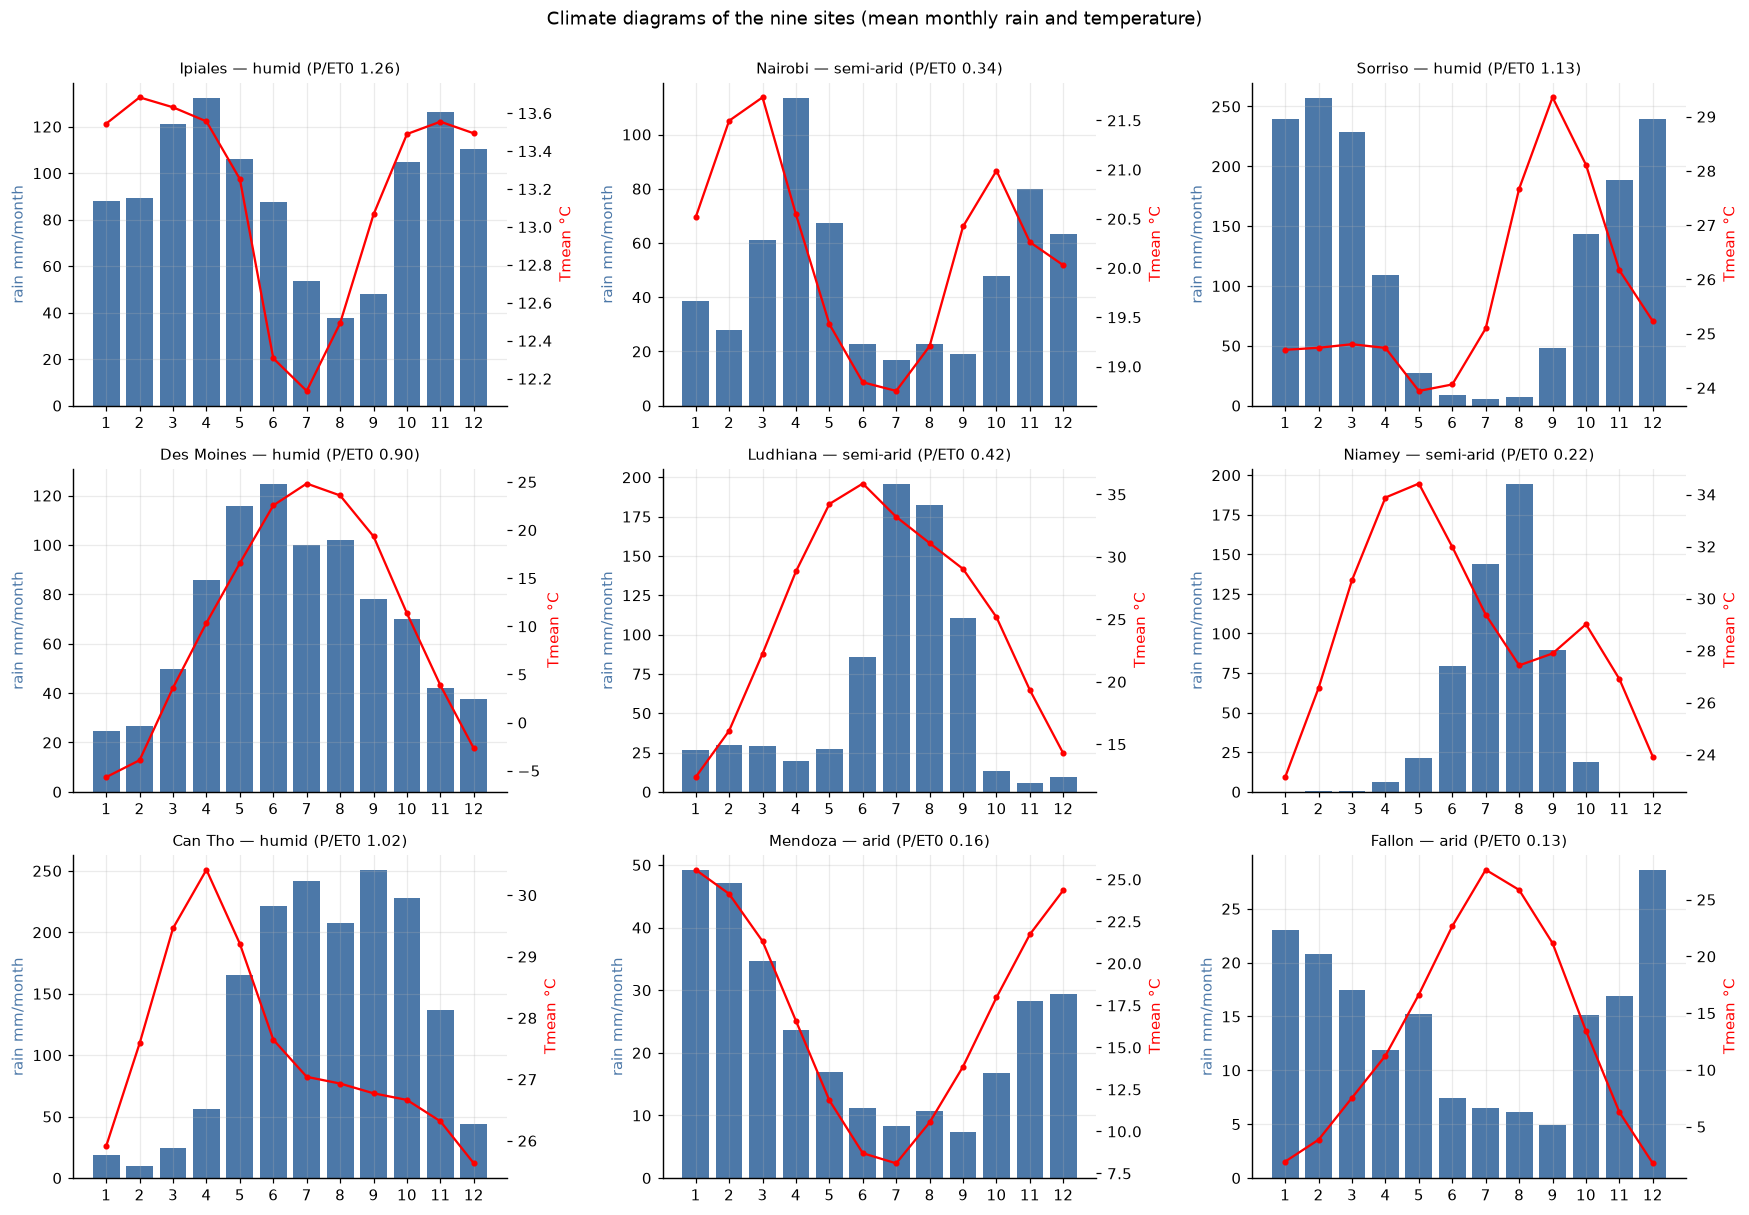

In [22]:
fig, axs = plt.subplots(3, 3, figsize=(16, 11)); axs = axs.ravel()
for ax, n in zip(axs, SITES):
    d = data[n]; mr = ct.monthly_series(d, "PRECTOTCORR"); mt = ct.monthly_series(d, "T2M")
    r_ = mr.groupby(mr.index.month).mean(); t_ = mt.groupby(mt.index.month).mean()
    ax.bar(r_.index, r_.values, color="#4c78a8"); ax.set_ylabel("rain mm/month", color="#4c78a8"); ax.set_xticks(range(1, 13))
    ax2 = ax.twinx(); ax2.plot(t_.index, t_.values, "r-o", ms=3); ax2.set_ylabel("Tmean °C", color="r"); ax2.grid(False)
    ax.set_title(f"{n} — {summ.loc[n, 'aridity_class']} (P/ET0 {summ.loc[n, 'P/ET0']:.2f})", fontsize=10)
fig.suptitle("Climate diagrams of the nine sites (mean monthly rain and temperature)", y=1.0); plt.tight_layout(); savefig("11_climate_diagrams_sites"); plt.show()

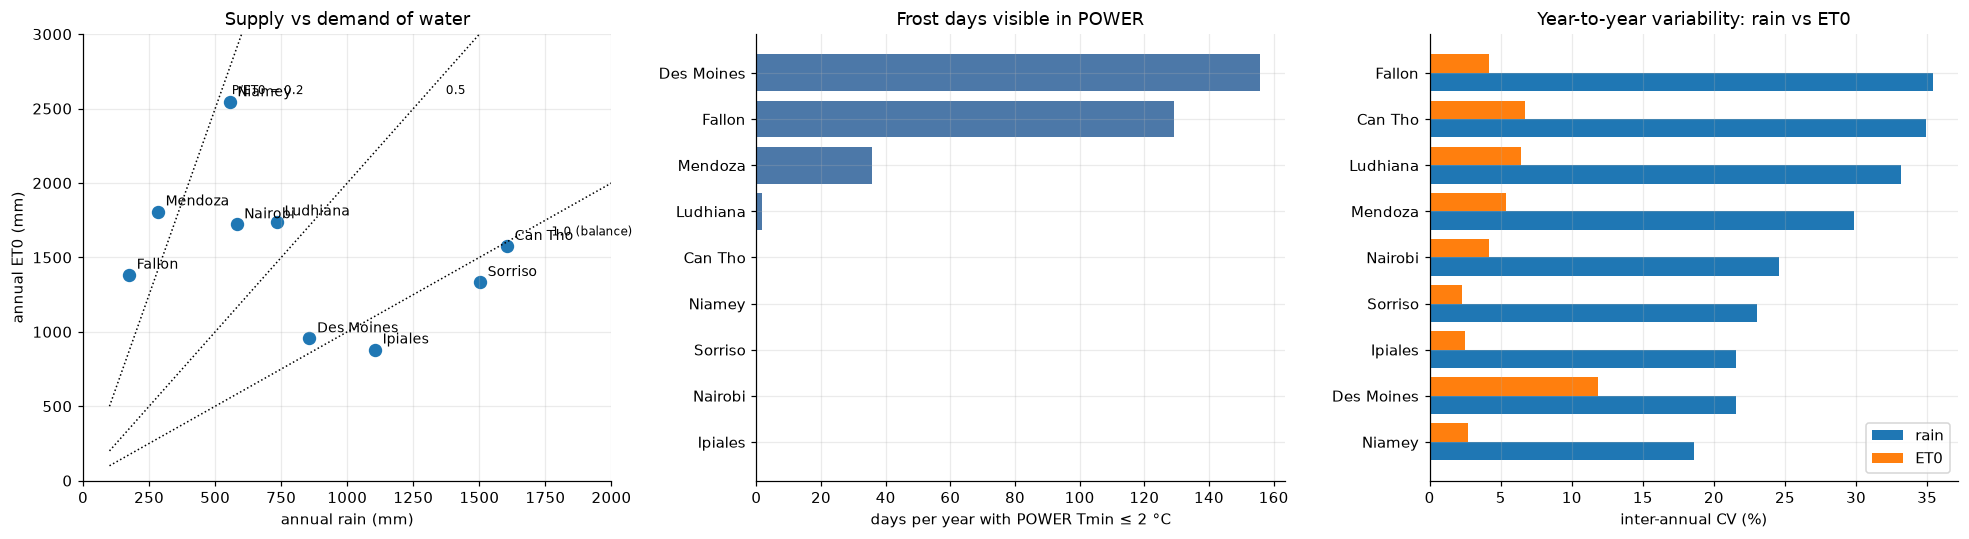

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
P_ = summ.rain_mm_yr.astype(float); E_ = summ.ET0_mm_yr.astype(float)
axs[0].scatter(P_, E_, s=60)
for n in SITES: axs[0].annotate(n, (P_[n], E_[n]), xytext=(5, 4), textcoords="offset points", fontsize=9)
g = np.linspace(100, 3000, 50)
for r_, lab in [(.2, "P/ET0 = 0.2"), (.5, "0.5"), (1.0, "1.0 (balance)")]:
    axs[0].plot(g, g / r_, "k:", lw=1)
    xl = min(1750, 2700 * r_); axs[0].annotate(lab, (xl, xl / r_), fontsize=8, xytext=(4, -10), textcoords="offset points")
axs[0].set_xlim(0, 2000); axs[0].set_ylim(0, 3000); axs[0].set_xlabel("annual rain (mm)"); axs[0].set_ylabel("annual ET0 (mm)"); axs[0].set_title("Supply vs demand of water")
fd = summ["frost_days_Tmin<=2C_yr"].astype(float).sort_values()
axs[1].barh(fd.index, fd.values, color="#4c78a8"); axs[1].set_xlabel("days per year with POWER Tmin ≤ 2 °C"); axs[1].set_title("Frost days visible in POWER")
cv = summ[["rain_CV_%", "ET0_CV_%"]].astype(float).loc[summ["rain_CV_%"].astype(float).sort_values().index]
yy = np.arange(len(cv)); axs[2].barh(yy - .2, cv["rain_CV_%"], .4, label="rain"); axs[2].barh(yy + .2, cv["ET0_CV_%"], .4, label="ET0")
axs[2].set_yticks(yy); axs[2].set_yticklabels(cv.index); axs[2].set_xlabel("inter-annual CV (%)"); axs[2].legend(); axs[2].set_title("Year-to-year variability: rain vs ET0")
plt.tight_layout(); savefig("12_site_comparison"); plt.show()

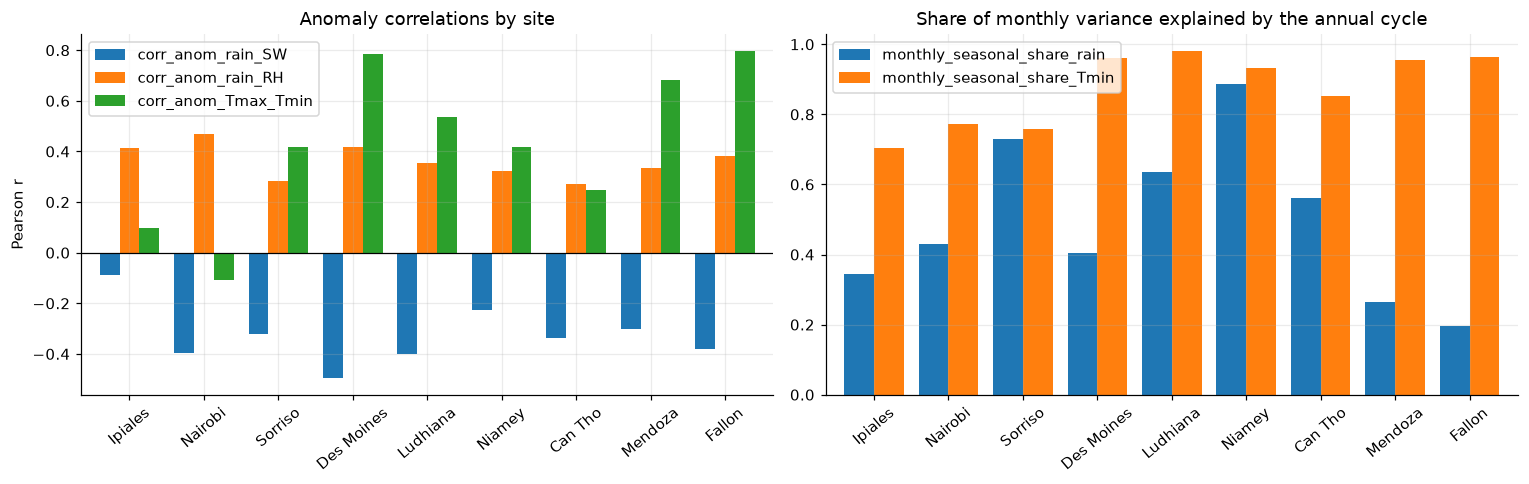

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
c1 = summ[["corr_anom_rain_SW", "corr_anom_rain_RH", "corr_anom_Tmax_Tmin"]].astype(float)
c1.plot(kind="bar", ax=axs[0], width=.8); axs[0].axhline(0, color="k", lw=.8); axs[0].set_title("Anomaly correlations by site"); axs[0].set_ylabel("Pearson r"); axs[0].tick_params(axis="x", rotation=40)
c2 = summ[["monthly_seasonal_share_rain", "monthly_seasonal_share_Tmin"]].astype(float)
c2.plot(kind="bar", ax=axs[1], width=.8); axs[1].set_title("Share of monthly variance explained by the annual cycle"); axs[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); savefig("13_site_dependence_seasonality"); plt.show()

## 12 · Findings, limitations and next steps

In [25]:
# Automatically generated key numbers (always consistent with the run above)
k = summ
print("KEY NUMBERS")
print(f"Ipiales: complete series, {len(df):,} days; annual rain {k.loc['Ipiales','rain_mm_yr']:.0f} mm (CV {k.loc['Ipiales','rain_CV_%']:.0f}%), ET0 {k.loc['Ipiales','ET0_mm_yr']:.0f} mm (CV {k.loc['Ipiales','ET0_CV_%']:.1f}%).")
print(f"Share of the variance of P-ET0 due to rainfall: " + ", ".join(f"{n} {k.loc[n,'share_Var(P-ET0)_from_P_%']:.0f}%" for n in SITES))
print(f"Frost days (POWER Tmin<=2C) per year: " + ", ".join(f"{n} {k.loc[n,'frost_days_Tmin<=2C_yr']:.1f}" for n in SITES))
print(f"Aridity classes: " + ", ".join(f"{n}: {k.loc[n,'aridity_class']}" for n in SITES))
print(f"Rain-radiation anomaly correlation: " + ", ".join(f"{n} {k.loc[n,'corr_anom_rain_SW']:.2f}" for n in SITES))
print(f"Ipiales rain trend: {tr.loc['rain_mm','sen_slope_per_yr']:+.1f} mm/yr (p={tr.loc['rain_mm','p']:.4f}, Holm p={tr.loc['rain_mm','p_Holm']:.3f})")

KEY NUMBERS
Ipiales: complete series, 9,131 days; annual rain 1105 mm (CV 22%), ET0 880 mm (CV 2.5%).
Share of the variance of P-ET0 due to rainfall: Ipiales 90%, Nairobi 49%, Sorriso 88%, Des Moines 42%, Ludhiana 48%, Niamey 41%, Can Tho 82%, Mendoza 25%, Fallon 32%
Frost days (POWER Tmin<=2C) per year: Ipiales 0.0, Nairobi 0.0, Sorriso 0.0, Des Moines 155.6, Ludhiana 1.8, Niamey 0.0, Can Tho 0.0, Mendoza 35.9, Fallon 129.1
Aridity classes: Ipiales: humid, Nairobi: semi-arid, Sorriso: humid, Des Moines: humid, Ludhiana: semi-arid, Niamey: semi-arid, Can Tho: humid, Mendoza: arid, Fallon: arid
Rain-radiation anomaly correlation: Ipiales -0.09, Nairobi -0.40, Sorriso -0.32, Des Moines -0.50, Ludhiana -0.40, Niamey -0.23, Can Tho -0.34, Mendoza -0.30, Fallon -0.38
Ipiales rain trend: +19.7 mm/yr (p=0.0063, Holm p=0.051)


### Findings (from the run above; all numbers come from the tables and figures in this notebook)

**Data quality.** All nine series are complete (9,131 days, 0 missing cells) and physically coherent (0 rule violations). The few "outliers" are cloudy, low-radiation days at arid sites (Mendoza 132 days, Niamey 46), i.e. real weather, not errors.

**Ipiales water regime.** Mean annual rain 1,105 mm with a 22 % year-to-year CV (737–1,613 mm); ET0 880 mm with a 2.5 % CV. Five years had rain below ET0 (2001, 2007, 2009, 2015, 2020). July–September is the deficit season: rain was below ET0 in 80–92 % of years. Days with ≥ 10 mm are 7 % of days but ~36 % of the rain. 57 % of days register ≥ 1 mm, which looks high for drizzle-prone reanalysis and should be checked against IMERG.

**Seasonality.** Temperature barely changes through the year in Ipiales (monthly Tmean range 1.5 °C), but the annual cycle still explains 70 % of the monthly variance of Tmin, 77 % of wind and 62 % of humidity; only 34 % of monthly rain. Rain is much more seasonal at monsoon sites (Niamey 89 %, Sorriso 73 %) and almost aseasonal at the desert sites (Fallon 20 %, Mendoza 27 %).

**Dependence (daily anomalies, Ipiales).** Strongest links: humidity–Tmax −0.50, Tmin–humidity +0.44, rain–humidity +0.41, humidity–wind −0.45. All block-bootstrap intervals exclude zero, but most pairs share under 25 % of their variance. Tmax and Tmin are nearly independent in Ipiales (+0.10) yet tightly coupled in temperate and desert sites (Des Moines 0.78, Fallon 0.80). The rain–radiation anomaly correlation is only −0.09 in Ipiales against −0.23 to −0.50 at the other eight sites. My earlier explanation (rain and radiation come from different products) cannot be the cause, because it would apply everywhere. This is specific to Ipiales and is unresolved.

**Memory.** Temperature and humidity anomalies persist (Tmean lag-1 0.72, still 0.25 at 30 days); rain anomalies have lag-1 0.37 but are ≈ 0 beyond a week. Ljung–Box rejects white noise for every variable, as expected with such strong day-to-day persistence.

**Trends.** Ipiales annual rain rises +19.7 mm/yr (Theil–Sen, 95 % CI 7.9–29.8; Mann–Kendall p = 0.006; Holm-adjusted p = 0.051); wet days +2.6/yr (Holm p = 0.017); humidity also rises; temperature and ET0 show no trend. The early-vs-late split (2001–2013 vs 2014–2025) is not significant (median rain 982 vs 1,232 mm, p = 0.13). Several other sites show very large trends (Ludhiana: rain +25 mm/yr, Tmean −0.79 °C/decade, ET0 −11 mm/yr, all p < 0.001; Sorriso: rain −24 mm/yr, Tmean +0.60 °C/decade; Can Tho: rain +53 mm/yr). A −2 °C change in 25 years at Ludhiana is not plausible as climate, so these are more likely artefacts of the reanalysis or local land-use effects. With 27 site-level tests, one or two false positives are expected at the 5 % level; only the p < 0.01 results deserve attention. **Consequence: the 25 years cannot be assumed to be one stationary sample.**

**Water balance across climates.** UNEP classes from P/ET0: humid (Ipiales 1.26, Sorriso 1.13, Can Tho 1.02, Des Moines 0.90), semi-arid (Nairobi 0.34, Ludhiana 0.42, Niamey 0.22 — Niamey is at the arid/semi-arid boundary), arid (Mendoza 0.16, Fallon 0.13). Rainfall explains 90 % (Ipiales), 88 % (Sorriso) and 82 % (Can Tho) of the year-to-year variance of P − ET0, but only 25–49 % elsewhere; Des Moines even has an ET0 CV of 11.9 %. **"Rain decides the water balance" is a humid-tropics result, not a general rule.**

**Frost.** POWER Tmin ≤ 2 °C appears 156 days/yr in Des Moines, 129 in Fallon, 36 in Mendoza, 1.8 in Ludhiana and never at the tropical sites. In Ipiales the coldest day in 25 years is 4.4 °C and only 27 days are ≤ 6 °C, while local farmers do report frost: the ~55 km cell cannot resolve plot-level cold.

**Extremes (Ipiales).** Gumbel return levels of daily rain: 5-year 43.8 mm (95 % CI 37.5–50.6), 10-year 50.9 mm (42.7–59.3), 25-year 60.0 mm (48.8–71.0). With 25 annual maxima the intervals are wide; the wettest observed day was 88.0 mm (2002-06-19).

**Predictability.** For monthly rain, last month's value is worse than the seasonal mean at all nine sites (skill −0.67 to −4.4) and adding last month's anomaly to the climatology reduces squared error by at most 8 % (Ipiales 4.6 %, Mendoza −0.7 %): no useful rainfall forecast from POWER alone. Monthly temperature does carry memory (clim+AR1 skill for Tmean: Sorriso 0.52, Ipiales 0.45, Can Tho 0.34, Nairobi 0.31, but only 0.04–0.07 in Fallon, Des Moines and Mendoza), partly reflecting year-to-year offsets and the non-stationarity above. Jan–Mar rain vs Apr–Dec rain in Ipiales: r = 0.38 (Spearman 0.40), bootstrap CI [0.05, 0.67], permutation p = 0.063, r² = 0.15 — a weak, borderline signal.

### Implications for the decision tool
1. **No rainfall forecasting from this source.** Show what the past has been (distribution, dry/wet years, extremes) with its uncertainty, not a prediction.
2. **The panel must change with climate.** Humid tropics: variability of water supply. Temperate/continental: cold season, frost and season length. Arid: irrigation demand.
3. **Cold risk needs local data** (farmer report or higher-resolution temperature); POWER's cell mean hides it in the tropical highlands.
4. **Test stationarity before using 25 years as one sample**, and cross-check trends with an independent source.

### Limitations
* Reanalysis cells (~55–110 km), not plot measurements; PRECTOTCORR is not a rain-gauge record.
* Site elevations are approximate, and POWER temperatures refer to the model cell's own elevation, so ET0 at mountain sites carries an unquantified bias.
* Nine sites are an illustrative, not a random, sample of world farmland.
* n = 25 years: wide intervals on extremes, trends and year-level correlations; several tests were run, so p-values near 0.05 are not conclusive.

### Open questions / next data sources
1. Elevation of the POWER cell (returned by the API, discarded by the current client) to correct temperature to the plot's altitude.
2. Compare PRECTOTCORR with IMERG at the same points: rain totals (Nairobi's 581 mm/yr looks lower than I would expect and must be verified), wet-day frequency (57 % in Ipiales), and the Ipiales/Ludhiana/Can Tho/Sorriso rain trends.
3. Check the Ludhiana and Sorriso temperature trends against an independent product (e.g. ERA5).
4. Explain the weak rain–radiation link specific to Ipiales (cloud data, local convective pattern, or the product's own resolution).

### Reproducibility
Run order: top to bottom. Inputs: `../data/power_<lat>_<lon>_20010101_20251231.csv` (downloaded by `power_client.py` if missing). Code: `../src/climate_tools.py`. Figures: `../figures/`.
All random procedures (bootstrap, permutation) use fixed seeds.